In [1]:
import sys

sys.path.append("../src")
from configs.load_config import load_config
from data_processing.load import load_dataset
from models.build import build_model
from training.train import train_torch, sample_numpyro
import matplotlib.pyplot as plt
from training.evaluate import evaluate_model, evaluate_numpyro
import importlib
import training.plot as load_plot

importlib.reload(load_plot)
from training.plot import (
    plot_qr_hdi_prediction,
    plot_quantile_calibration,
    plot_residuals,
    plot_qr_hdi_prediction,
    plot_quantile_calibration,
    plot_first_layer_feature_posteriors,
    plot_bnn_weight_posteriors,
    plot_posterior_predictive_vs_likelihood,
    plot_stacked_hdi_intervals,
    plot_pit_histogram,
    extract_quantile_curves,
    evaluate_and_plot_qr_ensemble_medians,
    plot_posterior_predictive_family,
    plot_qr_hdi_prediction_ensemble,
)
import torch
import numpy as np
import numpyro
from data_processing.utils import (
    load_torch_model,
    load_checkpoint,
    save_scaler_params,
    approximate_qr_intervals,
)
import pandas as pd

In [2]:
import training.plot as load_plot

importlib.reload(load_plot)
from training.plot import plot_qr_hdi_prediction_ensemble

In [3]:
# model_cfg = load_config("../configs/model/torch_model_quantile.yaml")
# file_name = "WindPowerQuantile_2025-12-21_10-21-23_forecast_gen_ELSPOT_NO1"

model_cfg = load_config("../configs/model/bnn_gen_model_nowcast_01.yaml")
data_cfg = load_config(model_cfg.data.path)
file_name = "model_mw_gamma_2026-02-04_10-02-43_nowcast_ELSPOT_NO1"  # model_mw_gamma_extended_2026-02-04_12-53-56_nowcast_ELSPOT_NO3"  # "model_mw_gamma_2026-01-16_03-18-21_nowcast_ELSPOT_NO3"  # "model_mw_gamma_2026-01-15_23-33-09_nowcast_ELSPOT_NO1"  # "model_mw_gamma_2026-01-15_20-24-15_nowcast_ELSPOT_NO1"  # "WindPowerQuantile_2026-01-14_10-30-39_nowcast_gen_ELSPOT_NO3"  # "WindPowerQuantile_2026-01-14_10-25-57_nowcast_gen_ELSPOT_NO1"


# model_cfg = load_config("../configs/model/torch_model_quantile.yaml")
# data_cfg = load_config(model_cfg.data.path)
# file_name = "WindPowerQuantile_2026-01-13_13-43-06_nowcast_gen_ELSPOT_NO3"

In [4]:
# from types import SimpleNamespace

# data_cfg.dataset = "forecast"
# data_cfg.ensemble = SimpleNamespace(members=None, variance=False)

In [5]:
data = load_dataset(data_cfg)

ELSPOT NO1
Loading nowcast data for ELSPOT NO1...


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/load.py:710: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  weather_forecast["hour"] = weather_forecast.index.hour
/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:63: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


All parks operational from 2022-10-26 22:00:00


QUEUEING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?it…

PROCESSING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?…

COLLECTING RESULTS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?,…

Maintenance hours in operational period: 8
Preprocessing done. X_train shape: (19122, 6, 10)
Preprocessing done. X_test shape: (2160, 6, 10)


In [6]:
save_scaler_params(
    scaler_params=data["scaler_params"],
    site_scaler_params=data["site_scaler_params"],
    bid_zone=data_cfg.bid_zone,
    split_time=pd.Timestamp("2025-01-01 00:00:00", tz="CET"),
    dataset=data_cfg.dataset,
    dir_path="../checkpoints",
)

Saved scaler parameters for ELSPOT NO1: ../checkpoints/scaler_params_ELSPOT_NO1_nowcast.pkl


'../checkpoints/scaler_params_ELSPOT_NO1_nowcast.pkl'

In [7]:
median_list = []
hdi_list = []
percentile_list = []
y_pred_list = []

for member in range(15):

    if model_cfg.backend == "torch":
        # Quantiles
        if model_cfg.params.quantiles is None:
            quantiles = torch.linspace(0, 1, 51)
        else:
            quantiles = torch.tensor(model_cfg.params.quantiles)

        model, checkpoint = load_torch_model(
            file_name=file_name,
        )

        metrics, y_pred = evaluate_model(
            model=model,
            data=data,
            quantiles=quantiles,
            model_cfg=checkpoint["model_cfg"],
            data_cfg=data_cfg,
            member=member,
        )

        hdis, _, _, _ = approximate_qr_intervals(
            Y_pred=y_pred,
            taus=quantiles,
            cred_mass=0.95,
        )

        # Extract curves, TODO: not 95% CI!!
        median, lower, upper = extract_quantile_curves(
            Y_pred_quantiles=y_pred,
            quantiles=quantiles,
            median_q=0.5,
            lower_q=0.02,
            upper_q=0.98,
        )

        percentiles = np.stack([lower, upper], axis=1)

        median_list.append(median)
        hdi_list.append(hdis.T)
        percentile_list.append(percentiles)
        y_pred_list.append(y_pred)

    elif model_cfg.backend == "numpyro":

        checkpoint = load_checkpoint(file_name=file_name)
        model = build_model(checkpoint["model_cfg"], data)
        samples = checkpoint["samples"]
        metrics, y_pred, predictive, median, percentiles, hdis = evaluate_numpyro(
            model=model,
            samples=checkpoint["samples"],
            rng_key_predict=checkpoint["rng_key_predict"],
            data=data,
            model_cfg=checkpoint["model_cfg"],
            member=member,
        )

        median_list.append(median)
        hdi_list.append(hdis)
        percentile_list.append(percentiles)
        y_pred_list.append(y_pred)

    # print(metrics)

    if data_cfg.dataset == "nowcast":
        # validate on nowcast, only one loop, otherwise validation on all ensemble members
        print("break")
        break


# assert checkpoint["model_cfg"] == model_cfg

Loading specified checkpoint: ../checkpoints/model_mw_gamma_2026-02-04_10-02-43_nowcast_ELSPOT_NO1.pkl
RMSE train: 47.586918
CRPS train:  23.8424264489896
break


In [8]:
data_cfg

namespace(dataset='nowcast',
          bid_zone='ELSPOT NO1',
          tensors=True,
          split_time=datetime.datetime(2025, 1, 1, 0, 0))

In [9]:
data["X_train"][0].shape

(6, 10)

In [10]:
median_df = pd.DataFrame(
    np.column_stack(median_list),
    columns=[f"median_{i}" for i in range(len(median_list))],
)

hdi_dict = {}

for i, arr in enumerate(hdi_list):
    hdi_dict[f"hdi_lower_{i}"] = arr[0]
    hdi_dict[f"hdi_upper_{i}"] = arr[1]

hdi_df = pd.DataFrame(hdi_dict)

ensemble_results = pd.concat([median_df, hdi_df], axis=1)

median_cols = ensemble_results.filter(regex=r"^median_").columns
hdi_lower_cols = ensemble_results.filter(regex=r"^hdi_lower_").columns
hdi_upper_cols = ensemble_results.filter(regex=r"^hdi_upper_").columns

ensemble_results["mean_median"] = ensemble_results[median_cols].mean(axis=1)
ensemble_results["std_median"] = ensemble_results[median_cols].std(axis=1)
ensemble_results["mean_hdi_lower"] = ensemble_results[hdi_lower_cols].mean(axis=1)
ensemble_results["std_hdi_lower"] = ensemble_results[hdi_lower_cols].std(axis=1)
ensemble_results["mean_hdi_upper"] = ensemble_results[hdi_upper_cols].mean(axis=1)
ensemble_results["std_hdi_upper"] = ensemble_results[hdi_upper_cols].std(axis=1)

In [11]:
ensemble_results

,median_0,hdi_lower_0,hdi_upper_0,mean_median,std_median,mean_hdi_lower,std_hdi_lower,mean_hdi_upper,std_hdi_upper
0,171.508224,27.820036,275.486450,171.508224,NaN,27.820036,NaN,275.486450,NaN
1,152.322632,59.822330,325.283478,152.322632,NaN,59.822330,NaN,325.283478,NaN
2,139.069244,67.589767,247.044998,139.069244,NaN,67.589767,NaN,247.044998,NaN
3,137.199844,52.241112,251.601593,137.199844,NaN,52.241112,NaN,251.601593,NaN
4,137.101364,31.177374,261.814758,137.101364,NaN,31.177374,NaN,261.814758,NaN
...,...,...,...,...,...,...,...,...,...
2155,25.310360,0.115301,87.505066,25.310360,NaN,0.115301,NaN,87.505066,NaN
2156,72.844131,1.173150,171.719864,72.844131,NaN,1.173150,NaN,171.719864,NaN
2157,96.732132,3.581232,186.108551,96.732132,NaN,3.581232,NaN,186.108551,NaN
2158,118.636429,16.932486,252.264389,118.636429,NaN,16.932486,NaN,252.264389,NaN


In [12]:
# import numpy as np

# for k, v in samples.items():
#     v = np.asarray(v)
#     print(
#         f"{k:20s} shape={v.shape} finite={np.isfinite(v).all()} "
#         f"min={np.nanmin(v):.3g} max={np.nanmax(v):.3g}"
#     )

In [13]:
# import numpy as np
# import arviz as az

# posterior = {k: np.asarray(v)[None, ...] for k, v in samples.items()}  # (1, 100, ...)

# idata = az.from_dict(posterior=posterior)
# az.plot_trace(idata, var_names=["b1", "b2", "b3mu", "b3k"])

In [14]:
# import matplotlib.pyplot as plt

# i = 0
# plt.plot(samples["mu"][:, i])
# plt.title(f"Trace mu[{i}]")
# plt.show()

### Plots


In [15]:
if model_cfg.backend == "numpyro":
    X_test = data["X_test"]
    if len(X_test.shape) == 4:
        X_test = X_test[:, :, 0]
    graph = numpyro.render_model(
        model,
        model_args=(X_test,),
    )
    graph

In [16]:
try:
    graph
except:
    pass

In [17]:
checkpoint.keys()

dict_keys(['samples', 'rng_key', 'rng_key_predict', 'model_cfg'])

In [18]:
import torch
import numpy as np
from numpyro.infer import Predictive
from data_processing.preprocess import (
    to_tensor,
)
import arviz as az
import pandas as pd
from jax import random


from data_processing.utils import (
    load_checkpoint,
    load_torch_model,
    QuantileDistribution,
)
from models.model import model_mw_gamma, model_cf_logitnormal, model_cf_beta
import torch
import re


def evaluate_numpyro_on_train_set(model, samples, rng_key_predict, data, model_cfg):

    X_test = data["X_train"]
    Y = data["Y_train_gen"] if model_cfg.params.target == "gen" else data["Y_test_cf"]

    # Handle forecast vs nowcast
    if model_cfg.name in ["model_mw_gamma", "model_cf_beta"] and X_test.ndim == 4:
        X_test = X_test[:, :, 0]  # first ensemble member

    predictive = Predictive(model, samples)(rng_key_predict, X_test)

    # Handle CF prediction, transform it back to generation prediction
    y_pred = (
        predictive["Y"]
        if model_cfg.params.target == "gen"
        else predictive["Y"] * data["Y_train_aval"]
    )
    y_pred_median = np.percentile(y_pred, 50, axis=0)
    percentiles = np.percentile(y_pred, [2.5, 97.5], axis=0)
    hdis = az.hdi(np.expand_dims(y_pred, axis=0), hdi_prob=0.95).T

    metrics = {}

    metrics["rmse_median"] = np.sqrt(np.mean((y_pred_median - Y) ** 2))
    metrics["coverage_025_975"] = ((Y >= percentiles[0]) & (Y <= percentiles[1])).mean()
    metrics["coverage_0_50"] = (Y <= y_pred_median).mean()

    # Percentiles shape: [t_test, 2]
    return metrics, y_pred, predictive, y_pred_median, percentiles.T, hdis


if model_cfg.backend == "numpyro":
    (
        metrics_train,
        y_pred_train,
        predictive_train,
        median_train,
        percentiles_train,
        hdis_train,
    ) = evaluate_numpyro_on_train_set(
        model, checkpoint["samples"], checkpoint["rng_key_predict"], data, model_cfg
    )

In [19]:
data["Y_test_gen"].max()

np.float32(379.18253)

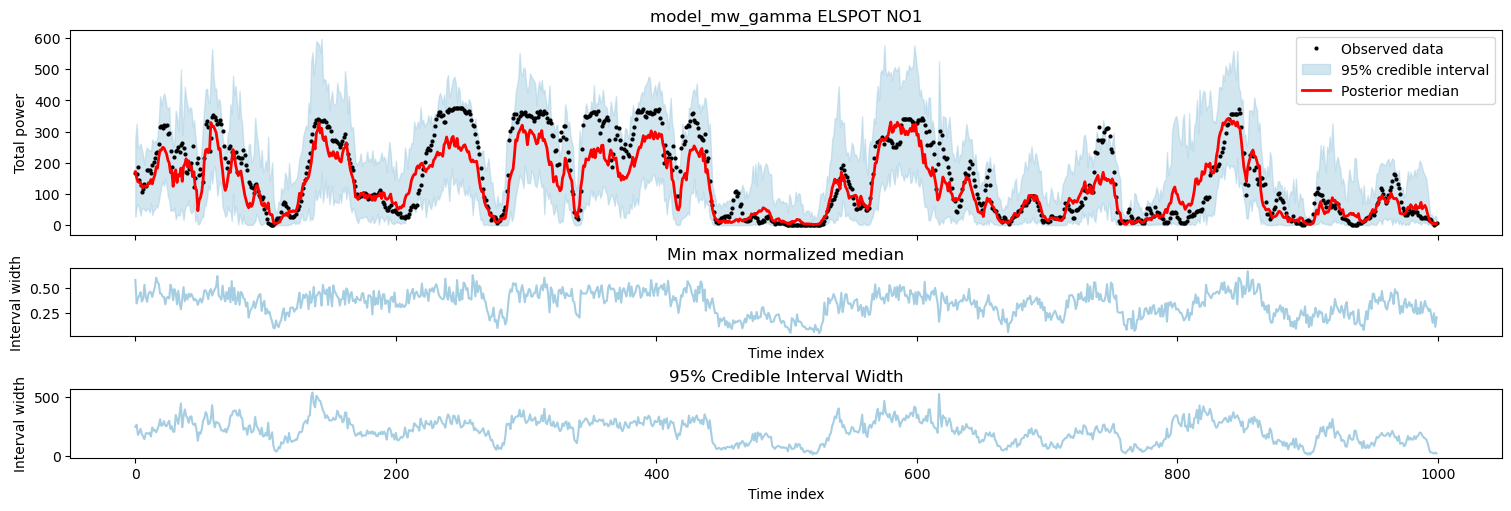

In [20]:
# Plot

fig, axes = plot_qr_hdi_prediction(
    Y_true=data["Y_test_gen"],
    conf_interval=hdi_list[0].T,
    medians=median_list[0],
    n_plot=1000,
    title=f"{model_cfg.name} {model_cfg.data.bid_zone}",
)
plt.show()

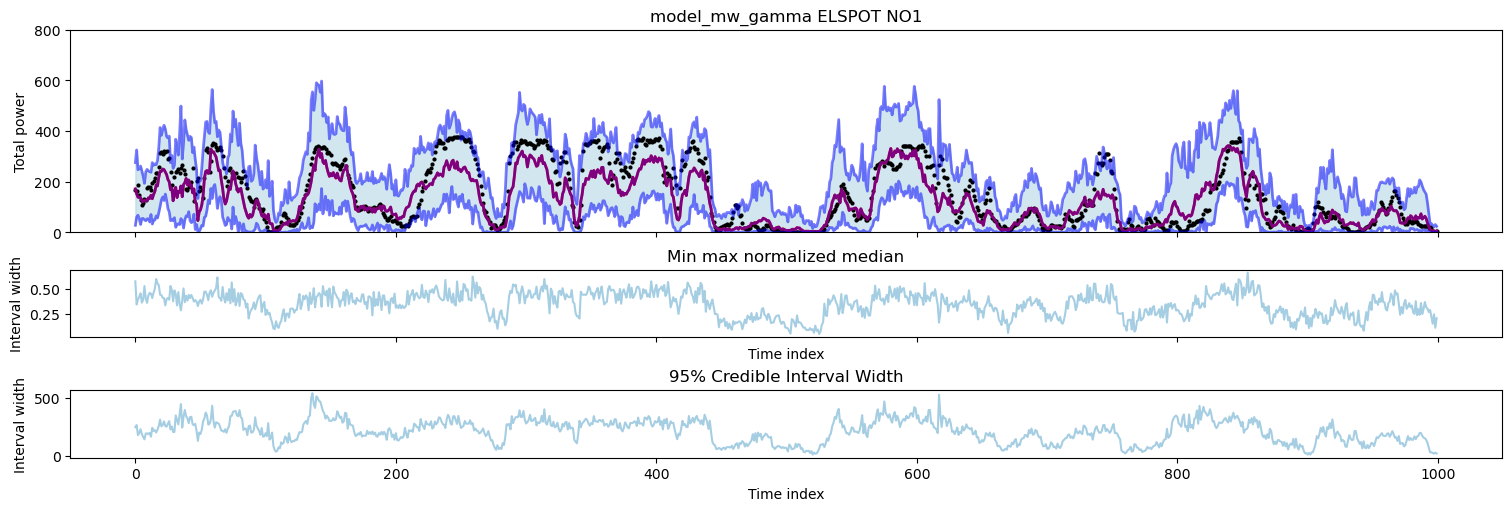

In [21]:
fig, axes = plot_qr_hdi_prediction_ensemble(
    Y_true=data["Y_test_gen"],
    ensemble_results=ensemble_results,
    n_plot=1000,
    title=f"{model_cfg.name} {model_cfg.data.bid_zone}",
)
plt.show()

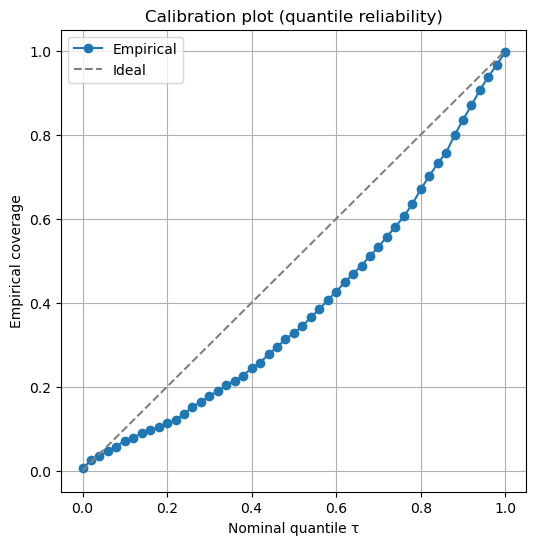

In [22]:
# y_pred: (S, N)

quantiles = torch.linspace(0, 1, 51)
emp_cov = plot_quantile_calibration(
    Y_pred_quantiles=(
        np.quantile(y_pred_list[0], quantiles, axis=0).T
        if model_cfg.backend == "numpyro"
        else y_pred
    ),
    Y_true=(
        data["Y_test_gen"] if model_cfg.params.target == "gen" else data["Y_test_cf"]
    ),
    quantiles=quantiles,
)

skew: 0.1772183


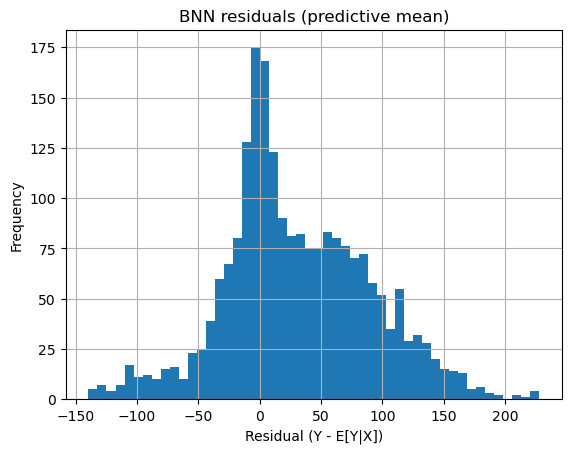

array([ -2.7712708,  11.221191 ,  48.624573 , ...,  -4.186653 ,
       -38.66577  , -48.576668 ], shape=(2160,), dtype=float32)

In [23]:
plot_residuals(
    median_list[0],
    data["Y_test_gen"],
)

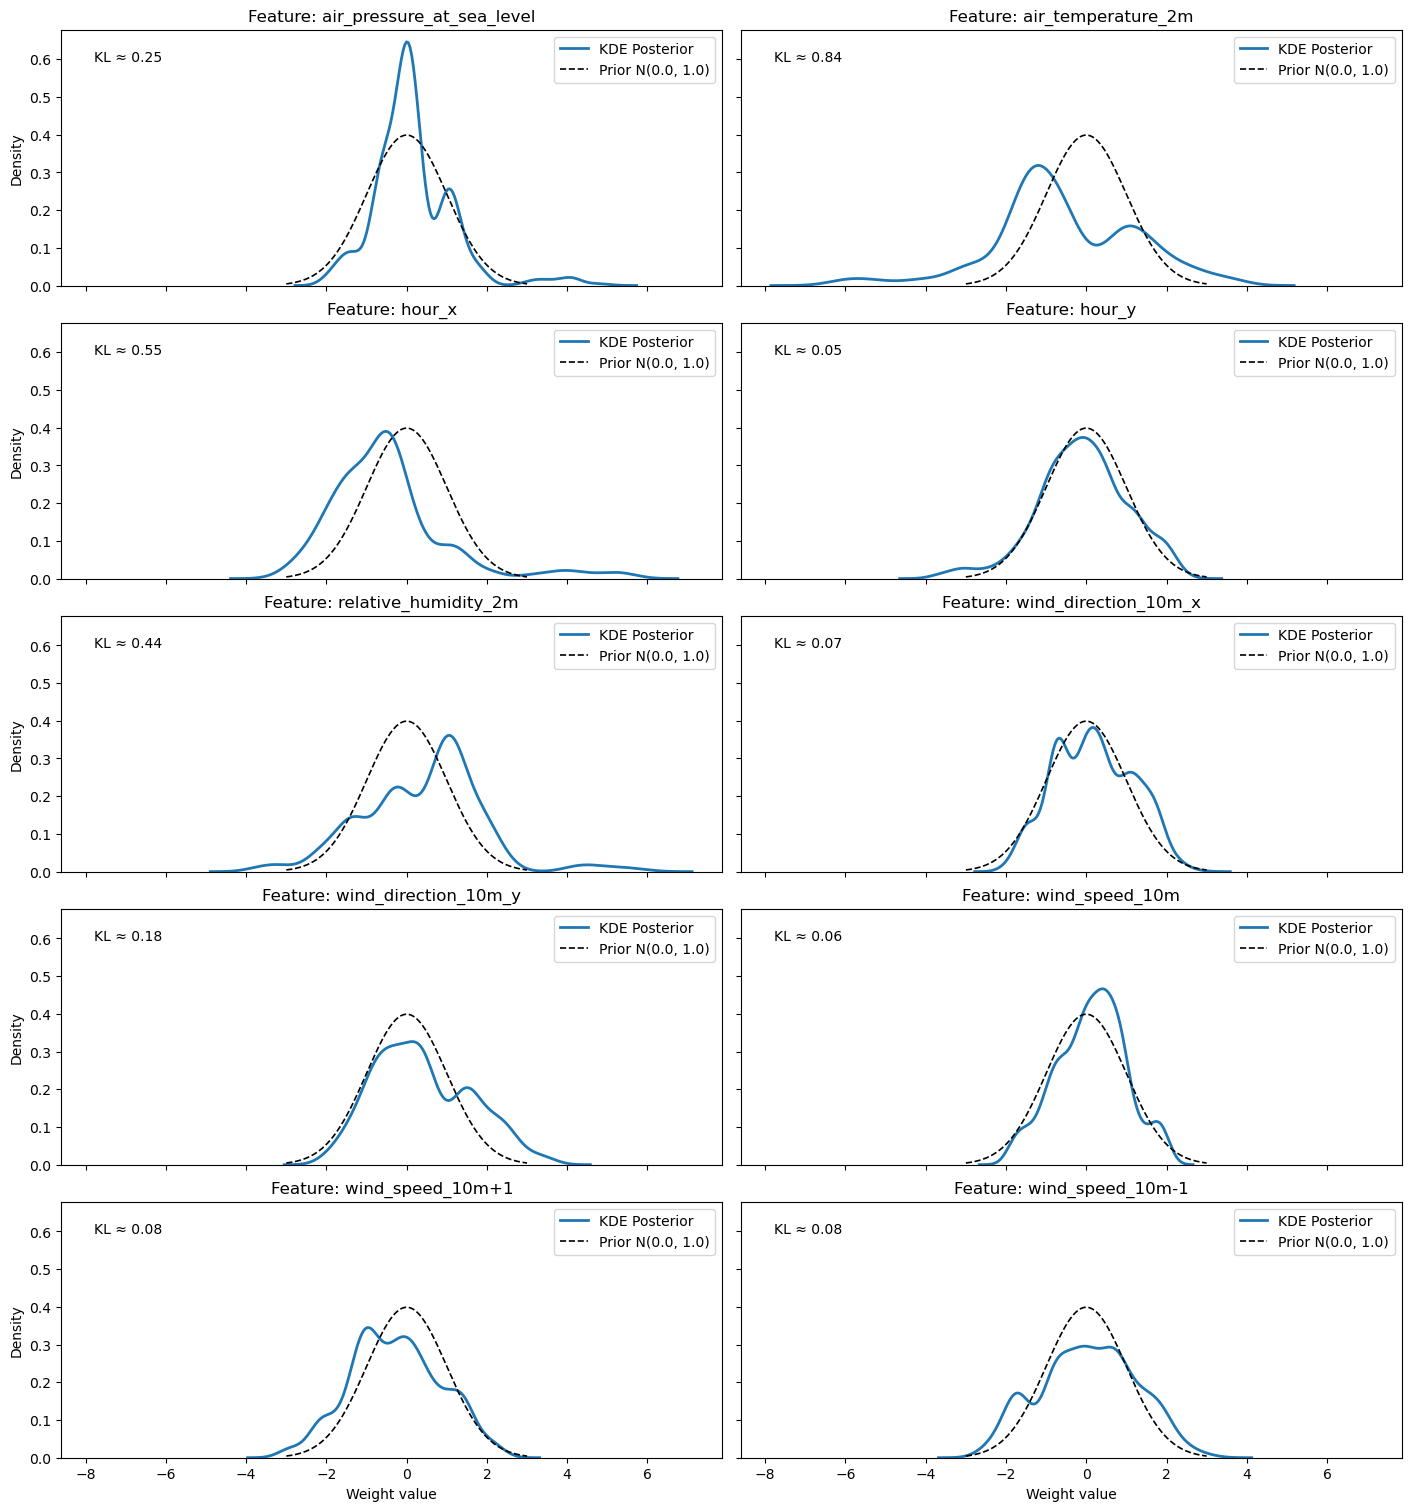

In [24]:
if model_cfg.backend == "numpyro":
    plot_first_layer_feature_posteriors(checkpoint["samples"], data)

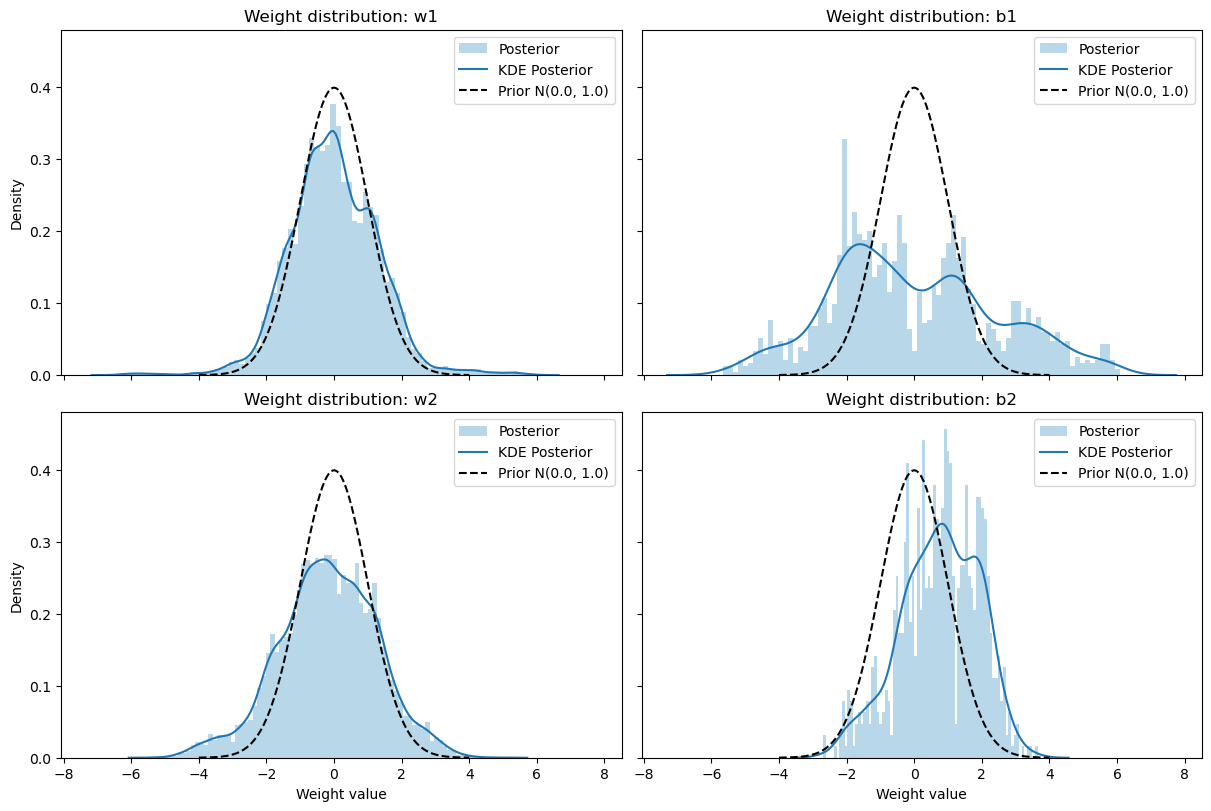

In [25]:
if model_cfg.backend == "numpyro":
    plot_bnn_weight_posteriors(checkpoint["samples"])

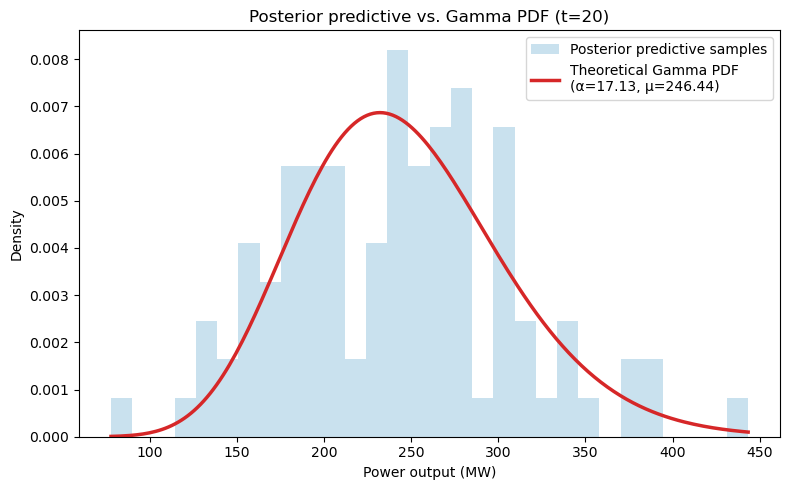

In [26]:
if model_cfg.backend == "numpyro":
    plot_posterior_predictive_vs_likelihood(
        predictive=predictive,
        model_name=model_cfg.name,
        t=20,
    )

Y not none


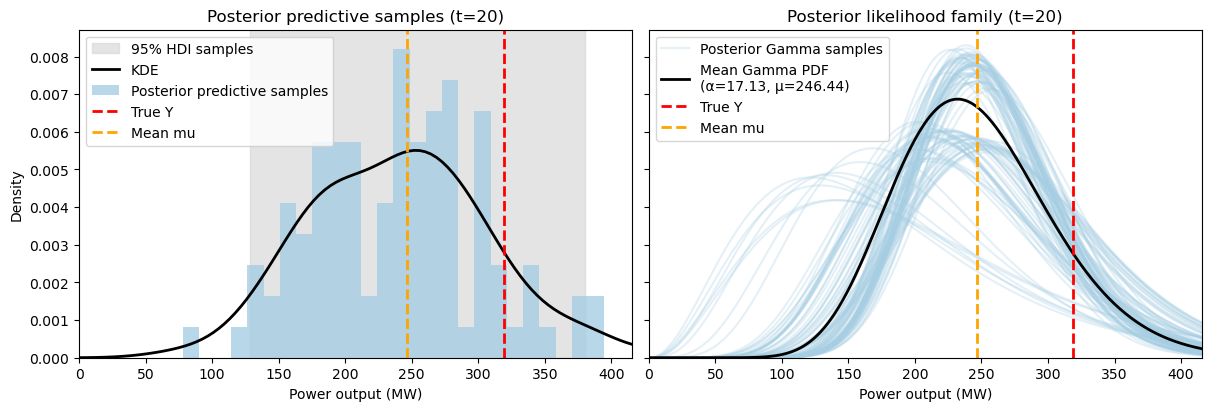

In [27]:
if model_cfg.backend == "numpyro":
    plot_posterior_predictive_family(predictive, model_cfg, data, t=20, hdi=percentiles)

In [28]:
if model_cfg.backend == "torch":
    plt.figure(figsize=(8, 5))
    plt.plot(checkpoint["losses"], label="Training Loss")
    plt.xlabel("Step")
    plt.ylabel("MSE Loss")
    plt.title("Training Loss Over Time")
    plt.legend()
    plt.grid(True)
    plt.show()

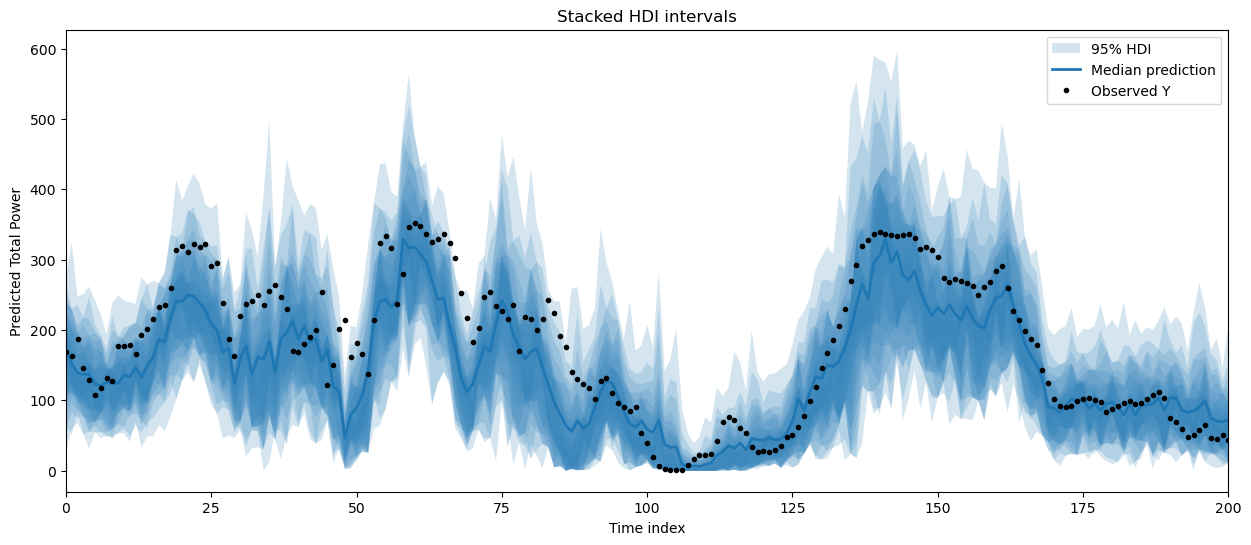

In [29]:
if model_cfg.backend == "numpyro":
    plot_stacked_hdi_intervals(
        preds=y_pred_list[0],
        Y_true=data["Y_test_gen"],
        n_plot=1000,
    )

PIT mean: 0.6098 (should be ~0.5 if calibrated)


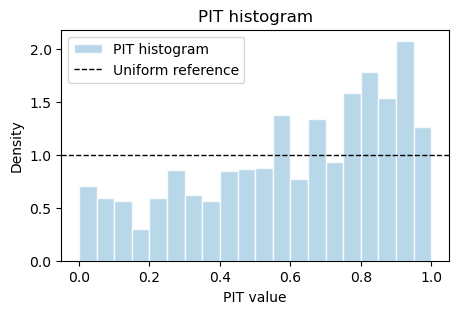

In [30]:
if model_cfg.backend == "numpyro":
    pits = plot_pit_histogram(
        preds=y_pred_list[0],
        Y_true=data["Y_test_gen"],
    )

In [31]:
if model_cfg.backend == "torch" and len(data["X_train"].shape) == 4:
    evaluate_and_plot_qr_ensemble_medians(
        model=model,
        data=data,
        quantiles=quantiles,
        n_members=15,
        n_plot=1000,
    )